In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import kagglehub

print('TensorFlow version:', tf.__version__)

path = kagglehub.dataset_download('zalando-research/fashionmnist')
print('Path to dataset files:', path)


TensorFlow version: 2.20.0
Using Colab cache for faster access to the 'fashionmnist' dataset.
Path to dataset files: /kaggle/input/fashionmnist


In [2]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print('Training shape:', X_train.shape)
print('Test shape:', X_test.shape)
print('Training dtype:', X_train.dtype)
print('Pixel range:', X_train.min(), 'to', X_train.max())


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training shape: (60000, 28, 28)
Test shape: (10000, 28, 28)
Training dtype: uint8
Pixel range: 0 to 255


In [3]:
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

X_train_cnn = X_train_norm[..., np.newaxis]
X_test_cnn = X_test_norm[..., np.newaxis]

print('Normalized training shape:', X_train_cnn.shape)
print('Normalized test shape:', X_test_cnn.shape)
print('Normalized range:', X_train_cnn.min(), 'to', X_train_cnn.max())


Normalized training shape: (60000, 28, 28, 1)
Normalized test shape: (10000, 28, 28, 1)
Normalized range: 0.0 to 1.0


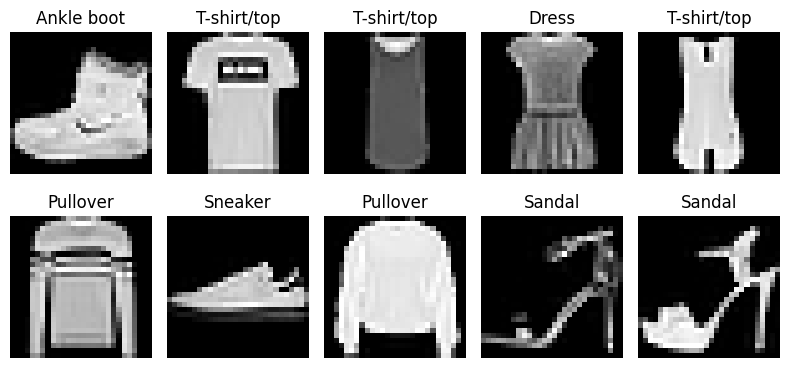

In [4]:
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()


## MLP Baseline

The baseline flattens each 28×28 image into 784 values, followed by Dense(128) and a 10-class softmax output. It is trained for 5 epochs as specified.


In [5]:
mlp = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

mlp.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mlp.summary()
mlp_params = mlp.count_params()
print('MLP parameters:', mlp_params)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

MLP parameters: 101770


In [6]:
mlp_history = mlp.fit(
    X_train_cnn, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.20,
    verbose=1
)

mlp_test_loss, mlp_test_acc = mlp.evaluate(X_test_cnn, y_test, verbose=0)
print(f'MLP Test Loss: {mlp_test_loss:.4f}')
print(f'MLP Test Accuracy: {mlp_test_acc:.4f}')


Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8145 - loss: 0.5365 - val_accuracy: 0.8495 - val_loss: 0.4313
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8588 - loss: 0.3969 - val_accuracy: 0.8615 - val_loss: 0.3960
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8714 - loss: 0.3608 - val_accuracy: 0.8635 - val_loss: 0.3860
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8798 - loss: 0.3320 - val_accuracy: 0.8589 - val_loss: 0.3768
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8865 - loss: 0.3121 - val_accuracy: 0.8808 - val_loss: 0.3414
MLP Test Loss: 0.3676
MLP Test Accuracy: 0.8675


##  LeNet-5 Inspired CNN


In [7]:
cnn = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(6, (5, 5), padding='same', activation='relu'),
    layers.AveragePooling2D(pool_size=(2, 2), strides=2),
    layers.Conv2D(16, (5, 5), padding='valid', activation='relu'),
    layers.AveragePooling2D(pool_size=(2, 2), strides=2),
    layers.Flatten(),
    layers.Dense(120, activation='relu'),
    layers.Dense(84, activation='relu'),
    layers.Dense(10, activation='softmax')
])

cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn.summary()
cnn_params = cnn.count_params()
print('CNN parameters:', cnn_params)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

CNN parameters: 61706


In [8]:
cnn_history = cnn.fit(
    X_train_cnn, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.20,
    verbose=1
)

cnn_test_loss, cnn_test_acc = cnn.evaluate(X_test_cnn, y_test, verbose=0)
print(f'CNN Test Loss: {cnn_test_loss:.4f}')
print(f'CNN Test Accuracy: {cnn_test_acc:.4f}')


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 28s 35ms/step - accuracy: 0.7648 - loss: 0.6388 - val_accuracy: 0.8330 - val_loss: 0.4638
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 37s 29ms/step - accuracy: 0.8381 - loss: 0.4386 - val_accuracy: 0.8473 - val_loss: 0.4071
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 22s 29ms/step - accuracy: 0.8579 - loss: 0.3799 - val_accuracy: 0.8663 - val_loss: 0.3667
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 40s 28ms/step - accuracy: 0.8740 - loss: 0.3458 - val_accuracy: 0.8766 - val_loss: 0.3420
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 39s 25ms/step - accuracy: 0.8815 - loss: 0.3181 - val_accuracy: 0.8793 - val_loss: 0.3220
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.8897 - loss: 0.3006 - val_accuracy: 0.8799 - val_loss: 0.3194
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.8938 - loss: 0.2840 - val_accuracy: 0.8870 - val_loss: 0.3078
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.8990 - loss: 0.2682 - 

##  CNN Training Curves


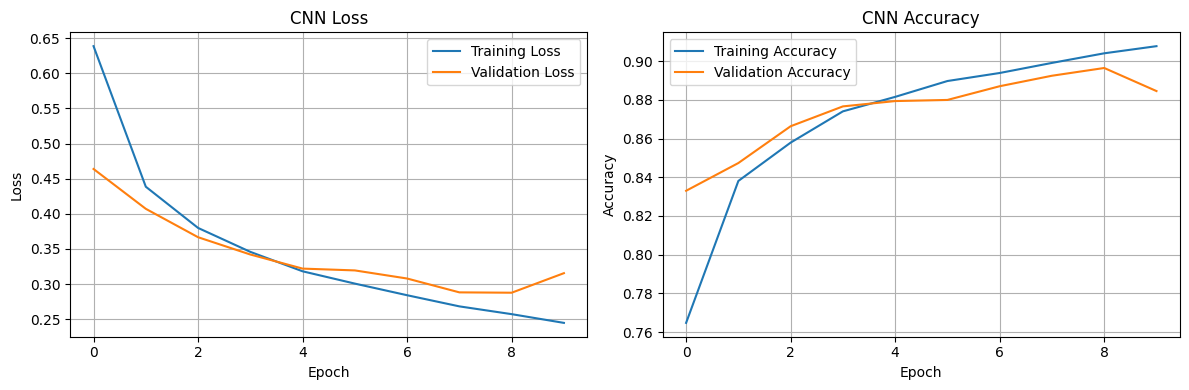

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(cnn_history.history['loss'], label='Training Loss')
axes[0].plot(cnn_history.history['val_loss'], label='Validation Loss')
axes[0].set_title('CNN Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(cnn_history.history['accuracy'], label='Training Accuracy')
axes[1].plot(cnn_history.history['val_accuracy'], label='Validation Accuracy')
axes[1].set_title('CNN Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


##  MLP vs CNN Comparison


In [10]:
comparison = pd.DataFrame({
    'Model': ['Flattened MLP', 'LeNet-5 CNN'],
    'Parameters': [mlp_params, cnn_params],
    'Test Loss': [mlp_test_loss, cnn_test_loss],
    'Test Accuracy': [mlp_test_acc, cnn_test_acc]
})

comparison


,Model,Parameters,Test Loss,Test Accuracy
0,Flattened MLP,101770,0.367578,0.8675
1,LeNet-5 CNN,61706,0.327007,0.8826


##  Classification Report


In [11]:
cnn_predictions = cnn.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(cnn_predictions, axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))


              precision    recall  f1-score   support

 T-shirt/top     0.9179    0.6600    0.7679      1000
     Trouser     0.9908    0.9720    0.9813      1000
    Pullover     0.8392    0.8040    0.8212      1000
       Dress     0.8605    0.9190    0.8888      1000
        Coat     0.8535    0.7980    0.8248      1000
      Sandal     0.9589    0.9800    0.9693      1000
       Shirt     0.6072    0.8210    0.6981      1000
     Sneaker     0.9475    0.9570    0.9522      1000
         Bag     0.9857    0.9660    0.9758      1000
  Ankle boot     0.9733    0.9490    0.9610      1000

    accuracy                         0.8826     10000
   macro avg     0.8935    0.8826    0.8841     10000
weighted avg     0.8935    0.8826    0.8841     10000



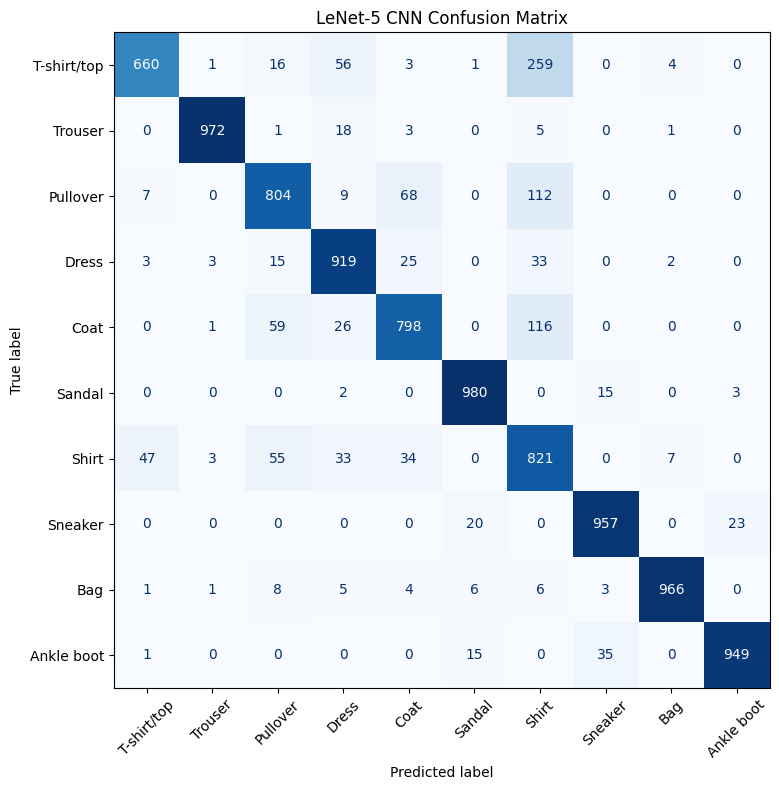

In [12]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title('LeNet-5 CNN Confusion Matrix')
plt.tight_layout()
plt.show()


##  Conclusion

The MLP treats the image as a flat vector and therefore does not explicitly preserve local spatial relationships. The LeNet-5 inspired CNN applies convolution and pooling before classification, allowing it to learn spatially local visual features. The comparison table above provides the measured parameter count, test loss, and test accuracy for both models.
